# Qdislib — Application 2 · VQE for a molecule (H₂), distributed with PyCOMPSs

**Find a molecule's ground-state energy on a device too small for the circuit.** The variational quantum eigensolver (VQE) prepares a trial state `|ψ(θ)⟩` with a parameterized **ansatz** and minimizes the energy `E(θ) = ⟨ψ(θ)|H|ψ(θ)⟩` toward the ground state. For H₂ (STO-3G basis, Jordan–Wigner mapping) the qubit Hamiltonian `H` is a weighted sum of **15 Pauli strings on 4 qubits**.

The idea: **cut the 4-qubit ansatz into two 2-qubit halves**, so it runs on ~2-qubit hardware. The energy is `⟨H⟩ = Σ_i c_i ⟨P_i⟩`, and each `⟨P_i⟩` is reconstructed from small subcircuits. That's **15 Hamiltonian terms × 36 cut configurations ≈ 500 independent subcircuits** — and **under PyCOMPSs they run in parallel**. Circuits are built and executed with **CUDA-Q**.

Look for the **🔧 Your turn** cells.

## Start the PyCOMPSs runtime

This starts the COMPSs runtime **for the whole notebook**: every `expectation_value` below runs as a parallel COMPSs `@task`. Run the notebook top to bottom; the last cell stops the runtime.

In [ ]:
import pycompss.interactive as ipycompss
ipycompss.start(graph=True, monitor=1000)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cudaq
from cudaq import spin
import Qdislib as qd

# H2 / STO-3G, Jordan-Wigner, bond length 0.7414 A. The qubit Hamiltonian is
# a weighted sum of Pauli strings (coefficients from a standard
# quantum-chemistry calculation). Qdislib takes it directly as
# observables=[(coeff, pauli), ...] (q0 = first character).
HAMILTONIAN = [
    (-0.04207897, "IIII"),
    ( 0.17771287, "ZIII"), ( 0.17771287, "IZII"),
    (-0.24274281, "IIZI"), (-0.24274281, "IIIZ"),
    ( 0.17059738, "ZZII"),
    ( 0.12293305, "ZIZI"), ( 0.16768319, "ZIIZ"),
    ( 0.16768319, "IZZI"), ( 0.12293305, "IZIZ"),
    ( 0.17627641, "IIZZ"),
    ( 0.04475014, "YXXY"), (-0.04475014, "YYXX"),
    (-0.04475014, "XXYY"), ( 0.04475014, "XYYX"),
]


def spin_operator(hamiltonian):
    """The Hamiltonian as a CUDA-Q SpinOperator (for the exact energy)."""
    paulis = {'X': spin.x, 'Y': spin.y, 'Z': spin.z}
    total = 0
    for coeff, pauli in hamiltonian:
        term = None
        for qubit, op in enumerate(pauli):
            if op == 'I':
                continue
            factor = paulis[op](qubit)
            term = factor if term is None else term * factor
        total += coeff * (term if term is not None else spin.i(0))
    return total


H_OP = spin_operator(HAMILTONIAN)

## 1. The ansatz — a 4-qubit CUDA-Q kernel

H₂'s ground state lives in the two-configuration space spanned by the Hartree–Fock state `|1100⟩` (both electrons in the low orbital) and the doubly-excited `|0011⟩`. A **single parameter** `θ` interpolates between them — `cos(θ/2)|0011⟩ + sin(θ/2)|1100⟩` — which is enough to reach the exact ground state. We build it as a CUDA-Q kernel: an `RY(θ)` sets the amplitude, and the two `CX` gates from qubit 0 into the `{2,3}` register are the only gates that **cross the two halves** — the cut points.

In [ ]:
def ansatz(theta):
    @cudaq.kernel
    def kernel():
        q = cudaq.qvector(4)
        ry(theta, q[0])       # amplitude of the excitation
        x.ctrl(q[0], q[1])    # correlate the {0,1} half
        x(q[2]); x(q[3])      # start the {2,3} half at |11>
        x.ctrl(q[0], q[2])    # <-- crosses the cut
        x.ctrl(q[0], q[3])    # <-- crosses the cut
    return kernel

# The ground-state manifold is exactly the two occupation patterns |0011>/|1100>:
print(cudaq.sample(ansatz(1.0), shots_count=2000))

## 2. The exact energy landscape

Sweep `θ` and evaluate `E(θ) = ⟨H⟩` exactly with `cudaq.observe` (no cutting yet). The minimum of the curve is the **ground-state energy** — for H₂ it should land near the textbook **−1.137 Ha**.

In [ ]:
thetas = np.linspace(0, 2 * np.pi, 200)
energies = [cudaq.observe(ansatz(t), H_OP).expectation() for t in thetas]

theta_opt = float(thetas[int(np.argmin(energies))])
E_ground = float(min(energies))

plt.figure(figsize=(6, 4))
plt.plot(thetas, energies)
plt.axvline(theta_opt, ls='--', c='grey')
plt.xlabel('theta'); plt.ylabel('energy (Ha)')
plt.title('H2 VQE energy landscape'); plt.show()

print(f'ground-state energy: {E_ground:.4f} Ha  at theta = {theta_opt:.3f}   (H2 ~ -1.137 Ha)')

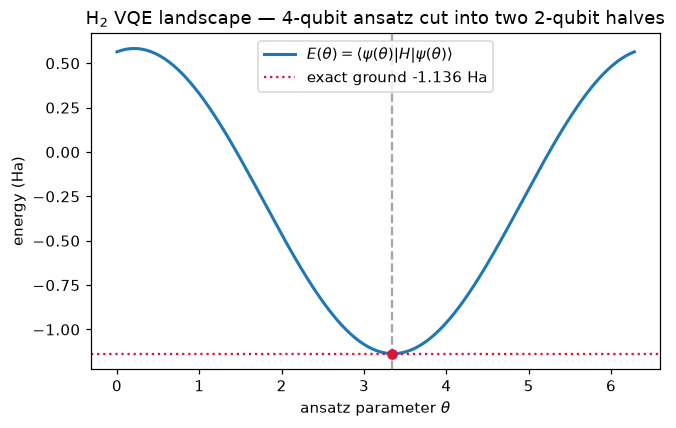

### 🔧 Your turn (1)

The ansatz has **one** parameter, so the landscape is a single curve. Increase the scan resolution (`200` → `400`) or zoom into `theta ∈ [3.0, 3.7]` and read off the minimum more precisely.

## 3. Cut the ansatz into two 2-qubit halves

`find_cut` looks at the ansatz and finds the two `CX` gates that couple the `{0,1}` and `{2,3}` registers — cutting them splits the 4-qubit circuit into two independent 2-qubit pieces.

In [ ]:
optimal = ansatz(theta_opt)
cut = qd.find_cut(optimal, gate_cut=True, wire_cut=False, max_qubits=2)
print('cut gates:', cut)   # the two cross-register CX

## 4. Reconstruct the energy by cutting — ~500 subcircuits in parallel

We use the **three-step workflow** for each Hamiltonian term `P_i`:

1. `gate_cutting_subcircuits` → the term's cut subcircuits (2 cuts ⇒ `6**2 = 36` configurations);
2. `expectation_value(s)` → evaluate each one — **a COMPSs task** on CUDA-Q;
3. `subs.reconstruct(values)` → the term's expectation `⟨P_i⟩`.

We **submit every term's evaluations first** (Phase 1) so all `14 × 36 = 504` subcircuits (the identity term is free) schedule together and PyCOMPSs runs them in parallel; then we **reconstruct and take the weighted sum** `⟨H⟩ = Σ_i c_i ⟨P_i⟩` (Phase 2).

In [ ]:
# Phase 1 -- generate every term's subcircuits and SUBMIT all evaluations.
#   Each expectation_value(...) is a COMPSs task; building the list schedules
#   all subcircuits at once, so they run in parallel across workers.
plans = []
for coeff, pauli in HAMILTONIAN:
    if set(pauli) == {'I'}:            # identity term: <I> = 1, no circuit
        plans.append((coeff, None, None))
        continue
    subs = qd.gate_cutting_subcircuits(optimal, cut, observables=pauli,
                                       software='cudaq')
    values = [qd.expectation_value(s, shots=100_000) for s in subs]
    plans.append((coeff, subs, values))

# Phase 2 -- reconstruct each term and take the weighted sum <H> = sum_i c_i <P_i>.
energy = sum(c if subs is None else c * subs.reconstruct(v)
             for c, subs, v in plans)

print(f'cut-reconstructed energy: {energy:+.4f} Ha')
print(f'exact (statevector):      {E_ground:+.4f} Ha')
print(f'error: {abs(energy - E_ground):.4f} Ha   (~shot noise x quasiprobability overhead)')

## Recap & bonus

You estimated H₂'s ground-state energy by **cutting a 4-qubit VQE ansatz into two 2-qubit halves** and reconstructing `⟨H⟩` from ~500 small subcircuits — the 15 Hamiltonian terms × 36 cut configurations — **sampled in parallel under PyCOMPSs, on CUDA-Q**, matching the exact energy to shot noise.

**🔧 Your turn (2):** a full VQE just wraps this energy in a classical minimizer. Sharpen the result — raise `shots` (the error is shot-noise × the quasiprobability overhead) or refine `theta_opt` with a finer scan near the minimum — and watch the cut energy approach the textbook **−1.137 Ha**.

**On real hardware:** the 2-qubit subcircuits are QPU-sized, but here the cut qubits keep evolving after the cut, so the terms that observe them with identity need the cut-point **sign decoupling** the CPU / CUDA-Q evaluators provide — aggregated QPU counts can't (yet). See **notebook 06** for the QPU API on circuits whose cut is terminal.

## Stop the PyCOMPSs runtime

Run this **last** — it shuts the COMPSs runtime down cleanly, syncing any outstanding results.

In [ ]:
ipycompss.stop(sync=True)